# Activité Pratique N°4 — Architecture Transformer

Mohamed Ouallal — IADATA — Groupe 4

## Configuration

In [1]:
from pathlib import Path
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__} | Device: {device}")

PyTorch: 2.15.0 | Device: cpu


## Première partie

### Série temporelle : sin(x)

X_train: torch.Size([150, 10, 1]) | X_test: torch.Size([40, 10, 1])


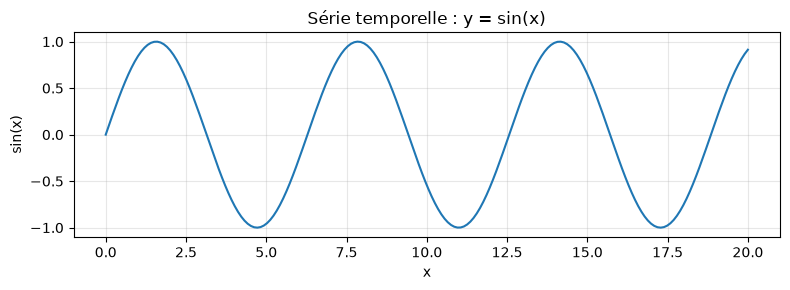

In [2]:
import torch.nn as nn

# Générer 200 valeurs de sin(x) entre 0 et 20
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

# Découper en séquences de 10 valeurs -> prédire la 11ème
longueur_sequence = 10
X = torch.stack([serie[i : i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])

# Format attendu par PyTorch : (batch, longueur, features)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : 150 pour l'entraînement, 40 pour le test
X_train, y_train = X[:150].to(device), y[:150].to(device)
X_test, y_test = X[150:].to(device), y[150:].to(device)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

plt.figure(figsize=(8, 3))
plt.plot(periode, serie)
plt.title("Série temporelle : y = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### RNN

Epoch  50 | Perte : 0.001277
Epoch 100 | Perte : 0.000504
Epoch 150 | Perte : 0.000223
Epoch 200 | Perte : 0.000103
Epoch 250 | Perte : 0.000049
Epoch 300 | Perte : 0.000025

Erreur test (MSE) : 0.000028


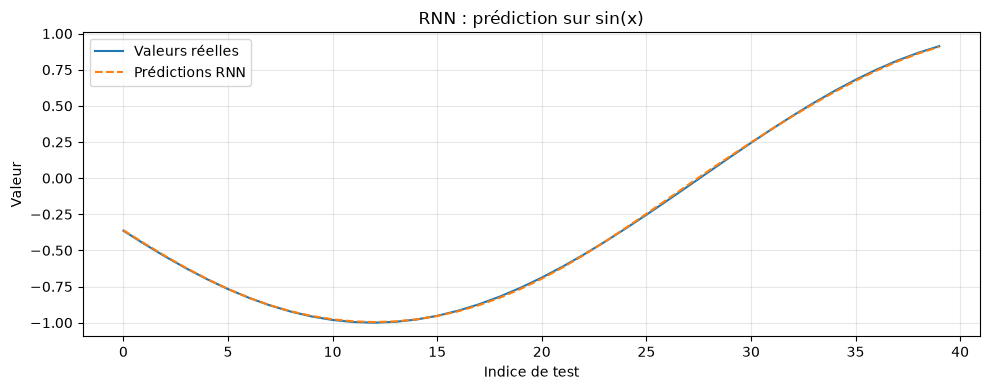

In [3]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.fc = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]
        return self.fc(dernier_etat)


modele_rnn = SimpleRNN().to(device)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)

# Entraînement
modele_rnn.train()
for epoch in range(300):
    predictions = modele_rnn(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Perte : {perte.item():.6f}")

# Évaluation sur le test
modele_rnn.eval()
with torch.no_grad():
    pred_rnn = modele_rnn(X_test)
    erreur_test = critere(pred_rnn, y_test)

print(f"\nErreur test (MSE) : {erreur_test.item():.6f}")

plt.figure(figsize=(10, 4))
plt.plot(y_test.cpu().numpy(), label="Valeurs réelles")
plt.plot(pred_rnn.cpu().numpy(), label="Prédictions RNN", linestyle="--")
plt.title("RNN : prédiction sur sin(x)")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### LSTM

### Transformer

### GPT : génération de texte

### BERT : prédiction d’un mot masqué